Loading in python source files and data sets

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

HarrisPartI = pd.read_csv("HarrisPartI.csv")
HarrisPartIII = pd.read_csv("HarrisPartIII.csv")
VDB = pd.read_csv("vandenBerg_table2.csv")
Krause21 = pd.read_csv("Krause21.csv")

pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)


In [3]:
harris_merged = pd.merge(HarrisPartI, HarrisPartIII, on='ID', how='outer')
display(harris_merged)

,ID,Name,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,v_r,v_r_e,v_LSR,sig_v,sig_v_e,c,r_c,r_h,mu_V,rho_0,lg_tc,lg_th
0,NGC 104,47 Tuc,00:24:05.67,-72:04:52.6,305.89,-44.89,4.5,7.4,1.9,-2.6,-3.1,-18.0,0.1,-26.7,11.0,0.3,2.07,0.36,3.17,14.38,4.88,7.84,9.55
1,NGC 288,NaN,00:52:45.24,-26:34:57.4,152.30,-89.38,8.9,12.0,-0.1,0.0,-8.9,-45.4,0.2,-51.9,2.9,0.3,0.99,1.35,2.23,20.05,1.78,8.99,9.32
2,NGC 362,NaN,01:03:14.26,-70:50:55.6,301.53,-46.25,8.6,9.4,3.1,-5.1,-6.2,223.5,0.5,214.0,6.4,0.3,1.76,0.18,0.82,14.80,4.74,7.76,8.93
3,Whiting 1,NaN,02:02:57,-03:15:10,161.22,-60.76,30.1,34.5,-13.9,4.7,-26.3,-130.6,1.8,-138.1,NaN,NaN,0.55,0.25,0.22,NaN,NaN,NaN,7.93
4,NGC 1261,NaN,03:12:16.21,-55:12:58.4,270.54,-52.12,16.3,18.1,0.1,-10.0,-12.9,68.2,4.6,54.9,NaN,NaN,1.16,0.35,0.68,17.73,2.99,8.59,9.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,NGC 7089,M 2,21:33:27.02,-00:49:23.7,53.37,-35.77,11.5,10.4,5.6,7.5,-6.7,-5.3,2.0,3.8,8.2,0.6,1.59,0.32,1.06,15.78,4.00,8.48,9.40
153,NGC 7099,M 30,21:40:22.12,-23:10:47.5,27.18,-46.84,8.1,7.1,4.9,2.5,-5.9,-184.2,0.2,-179.6,5.5,0.4,2.50,0.06,1.03,15.35,5.01,6.37,8.88
154,Pal 12,NaN,21:46:38.84,-21:15:09.4,30.51,-47.68,19.0,15.8,11.0,6.5,-14.1,27.8,1.5,32.5,NaN,NaN,2.98,0.02,1.72,19.21,3.64,5.22,9.28
155,Pal 13,NaN,23:06:44.44,+12:46:19.2,87.10,-42.70,26.0,26.9,1.0,19.1,-17.6,25.2,0.3,30.9,0.9,0.3,0.66,0.48,0.36,24.31,0.16,8.36,8.35


Function to normalise ID names

In [4]:
def normalise_IDs(id_string):
    """
    Normalises the IDs in the given DataFrame to match the IDs in the VDB and Krause21 datasets.
    Strip 'NGC prefix' from the Harris IDs to match the VDB and Krause21 IDs.
    If the ID column starts with 'NGC', remove the 'NGC' prefix and any leading/trailing whitespace.
    Returns the numerical part of the ID as an integer.
    if the ID column does not start with 'NGC', return the ID as is.

    """
    if id_string.startswith('NGC'):
        return int(id_string[3:].strip())
    else:
        return np.nan  # Return NaN for IDs that do not start with 'NGC'
    


In [5]:
VDB.rename(columns={'Age': 'Age_VDB', 'FeH': 'FeH_VDB'}, inplace=True)
Krause21.rename(columns={'Age': 'Age_Krause21', 'FeH': 'FeH_Krause21'}, inplace=True)

In [6]:

ngc_numbers = []
for id_val in harris_merged['ID']:
    ngc_numbers.append(normalise_IDs(id_val))
harris_merged['NGC_number'] = ngc_numbers
display(harris_merged)

,ID,Name,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,v_r,v_r_e,v_LSR,sig_v,sig_v_e,c,r_c,r_h,mu_V,rho_0,lg_tc,lg_th,NGC_number
0,NGC 104,47 Tuc,00:24:05.67,-72:04:52.6,305.89,-44.89,4.5,7.4,1.9,-2.6,-3.1,-18.0,0.1,-26.7,11.0,0.3,2.07,0.36,3.17,14.38,4.88,7.84,9.55,104.0
1,NGC 288,NaN,00:52:45.24,-26:34:57.4,152.30,-89.38,8.9,12.0,-0.1,0.0,-8.9,-45.4,0.2,-51.9,2.9,0.3,0.99,1.35,2.23,20.05,1.78,8.99,9.32,288.0
2,NGC 362,NaN,01:03:14.26,-70:50:55.6,301.53,-46.25,8.6,9.4,3.1,-5.1,-6.2,223.5,0.5,214.0,6.4,0.3,1.76,0.18,0.82,14.80,4.74,7.76,8.93,362.0
3,Whiting 1,NaN,02:02:57,-03:15:10,161.22,-60.76,30.1,34.5,-13.9,4.7,-26.3,-130.6,1.8,-138.1,NaN,NaN,0.55,0.25,0.22,NaN,NaN,NaN,7.93,NaN
4,NGC 1261,NaN,03:12:16.21,-55:12:58.4,270.54,-52.12,16.3,18.1,0.1,-10.0,-12.9,68.2,4.6,54.9,NaN,NaN,1.16,0.35,0.68,17.73,2.99,8.59,9.12,1261.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,NGC 7089,M 2,21:33:27.02,-00:49:23.7,53.37,-35.77,11.5,10.4,5.6,7.5,-6.7,-5.3,2.0,3.8,8.2,0.6,1.59,0.32,1.06,15.78,4.00,8.48,9.40,7089.0
153,NGC 7099,M 30,21:40:22.12,-23:10:47.5,27.18,-46.84,8.1,7.1,4.9,2.5,-5.9,-184.2,0.2,-179.6,5.5,0.4,2.50,0.06,1.03,15.35,5.01,6.37,8.88,7099.0
154,Pal 12,NaN,21:46:38.84,-21:15:09.4,30.51,-47.68,19.0,15.8,11.0,6.5,-14.1,27.8,1.5,32.5,NaN,NaN,2.98,0.02,1.72,19.21,3.64,5.22,9.28,NaN
155,Pal 13,NaN,23:06:44.44,+12:46:19.2,87.10,-42.70,26.0,26.9,1.0,19.1,-17.6,25.2,0.3,30.9,0.9,0.3,0.66,0.48,0.36,24.31,0.16,8.36,8.35,NaN


In [7]:
VDB['NGC_number'] = pd.to_numeric(VDB['#NGC'], errors='coerce') # Get rid of the "XXXX" in ID datafield

In [8]:
harris_merged_notNAN = harris_merged[~harris_merged['NGC_number'].isna()]
vdb_notNAN = VDB[~VDB['NGC_number'].isna()]

harris_vdb_merged = pd.merge(harris_merged_notNAN, vdb_notNAN, on='NGC_number', how='left')
display(harris_vdb_merged)

,ID,Name_x,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,v_r,v_r_e,v_LSR,sig_v,sig_v_e,c,r_c,r_h,mu_V,rho_0,lg_tc,lg_th,NGC_number,#NGC,Name_y,FeH_VDB,Age_VDB,Age_err,Method,Figs,Range,HBtype,R_G,M_V,v_e0,log_sigma_0
0,NGC 104,47 Tuc,00:24:05.67,-72:04:52.6,305.89,-44.89,4.5,7.4,1.9,-2.6,-3.1,-18.0,0.1,-26.7,11.0,0.3,2.07,0.36,3.17,14.38,4.88,7.84,9.55,104.0,104,47Tuc,-0.76,11.75,0.25,V,14,11.50–11.75,-0.99,7.4,-9.42,54.8,5.061
1,NGC 288,NaN,00:52:45.24,-26:34:57.4,152.30,-89.38,8.9,12.0,-0.1,0.0,-8.9,-45.4,0.2,-51.9,2.9,0.3,0.99,1.35,2.23,20.05,1.78,8.99,9.32,288.0,288,XXXX,-1.32,11.50,0.38,H,24,NaN,0.98,12.0,-6.75,10.9,2.953
2,NGC 362,NaN,01:03:14.26,-70:50:55.6,301.53,-46.25,8.6,9.4,3.1,-5.1,-6.2,223.5,0.5,214.0,6.4,0.3,1.76,0.18,0.82,14.80,4.74,7.76,8.93,362.0,362,XXXX,-1.30,10.75,0.25,V,13,10.75–11.00,-0.87,9.4,-8.43,44.4,4.938
3,NGC 1261,NaN,03:12:16.21,-55:12:58.4,270.54,-52.12,16.3,18.1,0.1,-10.0,-12.9,68.2,4.6,54.9,NaN,NaN,1.16,0.35,0.68,17.73,2.99,8.59,9.12,1261.0,1261,XXXX,-1.27,10.75,0.25,V,13,10.75–11.25,-0.71,18.1,-7.80,23.6,3.913
4,NGC 1851,NaN,05:14:06.76,-40:02:47.6,244.51,-35.03,12.1,16.6,-4.2,-8.9,-6.9,320.5,0.6,303.8,10.4,0.5,1.86,0.09,0.51,14.25,5.09,7.43,8.82,1851.0,1851,XXXX,-1.18,11.00,0.25,V,13,10.75–11.25,-0.32,16.6,-8.33,47.6,5.136
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,NGC 7006,NaN,21:01:29.38,+16:11:14.4,63.77,-19.41,41.2,38.5,17.2,34.8,-13.7,-384.1,0.4,-371.3,NaN,NaN,1.41,0.17,0.44,18.62,2.58,8.66,9.42,7006.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100,NGC 7078,M 15,21:29:58.33,+12:10:01.2,65.01,-27.31,10.4,10.4,3.9,8.3,-4.8,-107.0,0.2,-96.0,13.5,0.9,2.29,0.14,1.00,14.21,5.05,7.84,9.32,7078.0,7078,M15,-2.33,12.75,0.25,V,11,12.50–12.75,0.67,10.4,-9.19,41.6,4.827
101,NGC 7089,M 2,21:33:27.02,-00:49:23.7,53.37,-35.77,11.5,10.4,5.6,7.5,-6.7,-5.3,2.0,3.8,8.2,0.6,1.59,0.32,1.06,15.78,4.00,8.48,9.40,7089.0,7089,M2,-1.66,11.75,0.25,A,12-30,11.50–11.75,0.92,10.4,-9.03,41.8,4.531
102,NGC 7099,M 30,21:40:22.12,-23:10:47.5,27.18,-46.84,8.1,7.1,4.9,2.5,-5.9,-184.2,0.2,-179.6,5.5,0.4,2.50,0.06,1.03,15.35,5.01,6.37,8.88,7099.0,7099,M30,-2.33,13.00,0.25,A,11-30,12.75–13.00,0.89,7.1,-7.45,25.4,4.831


In [9]:
display(normalise_IDs('NGC104'))  # Should return 104
ngc_numbers_krause21 = []
for id_val in Krause21['Object']:
    ngc_numbers_krause21.append(normalise_IDs(id_val))
Krause21['NGC_number'] = ngc_numbers_krause21
display(Krause21)


104

,Class,Object,AltName,Mstar,rh,C5,Age_Krause21,FeH_Krause21,NGC_number
0,GC,NGC104,47Tuc,6.46,7.10,0.920,12.80,-0.76,104.0
1,GC,NGC288,Melotte3,0.46,9.80,0.050,12.20,-1.32,288.0
2,GC,NGC362,Dunlop62,2.50,3.50,0.720,10.00,-1.26,362.0
3,GC,NGC1261,Caldwell87,3.41,5.50,0.620,10.24,-1.08,1261.0
4,GC,NGC1851,Dunlop508,5.51,3.05,1.810,7.64,-1.13,1851.0
...,...,...,...,...,...,...,...,...,...
56,GC,NGC7089,M2,5.75,6.03,0.950,11.80,-1.31,7089.0
57,GC,NGC7099,M30,1.45,4.10,0.350,14.60,-2.33,7099.0
58,GC,Ruprecht106,NONE,0.68,11.00,0.060,12.00,-1.50,NaN
59,GC,Terzan7,NONE,0.39,8.70,0.040,7.40,-0.12,NaN


In [10]:
harris_vdb_k21_merged = pd.merge(harris_vdb_merged, Krause21, on='NGC_number', how='left')
display(harris_vdb_k21_merged)

,ID,Name_x,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,v_r,v_r_e,v_LSR,sig_v,sig_v_e,c,r_c,r_h,mu_V,rho_0,lg_tc,lg_th,NGC_number,#NGC,Name_y,FeH_VDB,Age_VDB,Age_err,Method,Figs,Range,HBtype,R_G,M_V,v_e0,log_sigma_0,Class,Object,AltName,Mstar,rh,C5,Age_Krause21,FeH_Krause21
0,NGC 104,47 Tuc,00:24:05.67,-72:04:52.6,305.89,-44.89,4.5,7.4,1.9,-2.6,-3.1,-18.0,0.1,-26.7,11.0,0.3,2.07,0.36,3.17,14.38,4.88,7.84,9.55,104.0,104,47Tuc,-0.76,11.75,0.25,V,14,11.50–11.75,-0.99,7.4,-9.42,54.8,5.061,GC,NGC104,47Tuc,6.46,7.10,0.92,12.80,-0.76
1,NGC 288,NaN,00:52:45.24,-26:34:57.4,152.30,-89.38,8.9,12.0,-0.1,0.0,-8.9,-45.4,0.2,-51.9,2.9,0.3,0.99,1.35,2.23,20.05,1.78,8.99,9.32,288.0,288,XXXX,-1.32,11.50,0.38,H,24,NaN,0.98,12.0,-6.75,10.9,2.953,GC,NGC288,Melotte3,0.46,9.80,0.05,12.20,-1.32
2,NGC 362,NaN,01:03:14.26,-70:50:55.6,301.53,-46.25,8.6,9.4,3.1,-5.1,-6.2,223.5,0.5,214.0,6.4,0.3,1.76,0.18,0.82,14.80,4.74,7.76,8.93,362.0,362,XXXX,-1.30,10.75,0.25,V,13,10.75–11.00,-0.87,9.4,-8.43,44.4,4.938,GC,NGC362,Dunlop62,2.50,3.50,0.72,10.00,-1.26
3,NGC 1261,NaN,03:12:16.21,-55:12:58.4,270.54,-52.12,16.3,18.1,0.1,-10.0,-12.9,68.2,4.6,54.9,NaN,NaN,1.16,0.35,0.68,17.73,2.99,8.59,9.12,1261.0,1261,XXXX,-1.27,10.75,0.25,V,13,10.75–11.25,-0.71,18.1,-7.80,23.6,3.913,GC,NGC1261,Caldwell87,3.41,5.50,0.62,10.24,-1.08
4,NGC 1851,NaN,05:14:06.76,-40:02:47.6,244.51,-35.03,12.1,16.6,-4.2,-8.9,-6.9,320.5,0.6,303.8,10.4,0.5,1.86,0.09,0.51,14.25,5.09,7.43,8.82,1851.0,1851,XXXX,-1.18,11.00,0.25,V,13,10.75–11.25,-0.32,16.6,-8.33,47.6,5.136,GC,NGC1851,Dunlop508,5.51,3.05,1.81,7.64,-1.13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,NGC 7006,NaN,21:01:29.38,+16:11:14.4,63.77,-19.41,41.2,38.5,17.2,34.8,-13.7,-384.1,0.4,-371.3,NaN,NaN,1.41,0.17,0.44,18.62,2.58,8.66,9.42,7006.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100,NGC 7078,M 15,21:29:58.33,+12:10:01.2,65.01,-27.31,10.4,10.4,3.9,8.3,-4.8,-107.0,0.2,-96.0,13.5,0.9,2.29,0.14,1.00,14.21,5.05,7.84,9.32,7078.0,7078,M15,-2.33,12.75,0.25,V,11,12.50–12.75,0.67,10.4,-9.19,41.6,4.827,GC,NGC7078,M15,5.13,5.10,1.00,13.60,-2.33
101,NGC 7089,M 2,21:33:27.02,-00:49:23.7,53.37,-35.77,11.5,10.4,5.6,7.5,-6.7,-5.3,2.0,3.8,8.2,0.6,1.59,0.32,1.06,15.78,4.00,8.48,9.40,7089.0,7089,M2,-1.66,11.75,0.25,A,12-30,11.50–11.75,0.92,10.4,-9.03,41.8,4.531,GC,NGC7089,M2,5.75,6.03,0.95,11.80,-1.31
102,NGC 7099,M 30,21:40:22.12,-23:10:47.5,27.18,-46.84,8.1,7.1,4.9,2.5,-5.9,-184.2,0.2,-179.6,5.5,0.4,2.50,0.06,1.03,15.35,5.01,6.37,8.88,7099.0,7099,M30,-2.33,13.00,0.25,A,11-30,12.75–13.00,0.89,7.1,-7.45,25.4,4.831,GC,NGC7099,M30,1.45,4.10,0.35,14.60,-2.33


,ID,Name_x,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,v_r,v_r_e,v_LSR,sig_v,sig_v_e,c,r_c,r_h,mu_V,rho_0,lg_tc,lg_th,NGC_number,#NGC,Name_y,FeH_VDB,Age_VDB,Age_err,Method,Figs,Range,HBtype,R_G,M_V,v_e0,log_sigma_0,Class,Object,AltName,Mstar,rh,C5,Age_Krause21,FeH_Krause21
0,NGC 104,47 Tuc,00:24:05.67,-72:04:52.6,305.89,-44.89,4.5,7.4,1.9,-2.6,-3.1,-18.0,0.1,-26.7,11.0,0.3,2.07,0.36,3.17,14.38,4.88,7.84,9.55,104.0,104,47Tuc,-0.76,11.75,0.25,V,14,11.50–11.75,-0.99,7.4,-9.42,54.8,5.061,GC,NGC104,47Tuc,6.46,7.10,0.92,12.80,-0.76
1,NGC 288,NaN,00:52:45.24,-26:34:57.4,152.30,-89.38,8.9,12.0,-0.1,0.0,-8.9,-45.4,0.2,-51.9,2.9,0.3,0.99,1.35,2.23,20.05,1.78,8.99,9.32,288.0,288,XXXX,-1.32,11.50,0.38,H,24,NaN,0.98,12.0,-6.75,10.9,2.953,GC,NGC288,Melotte3,0.46,9.80,0.05,12.20,-1.32
2,NGC 362,NaN,01:03:14.26,-70:50:55.6,301.53,-46.25,8.6,9.4,3.1,-5.1,-6.2,223.5,0.5,214.0,6.4,0.3,1.76,0.18,0.82,14.80,4.74,7.76,8.93,362.0,362,XXXX,-1.30,10.75,0.25,V,13,10.75–11.00,-0.87,9.4,-8.43,44.4,4.938,GC,NGC362,Dunlop62,2.50,3.50,0.72,10.00,-1.26
3,NGC 1261,NaN,03:12:16.21,-55:12:58.4,270.54,-52.12,16.3,18.1,0.1,-10.0,-12.9,68.2,4.6,54.9,NaN,NaN,1.16,0.35,0.68,17.73,2.99,8.59,9.12,1261.0,1261,XXXX,-1.27,10.75,0.25,V,13,10.75–11.25,-0.71,18.1,-7.80,23.6,3.913,GC,NGC1261,Caldwell87,3.41,5.50,0.62,10.24,-1.08
4,NGC 1851,NaN,05:14:06.76,-40:02:47.6,244.51,-35.03,12.1,16.6,-4.2,-8.9,-6.9,320.5,0.6,303.8,10.4,0.5,1.86,0.09,0.51,14.25,5.09,7.43,8.82,1851.0,1851,XXXX,-1.18,11.00,0.25,V,13,10.75–11.25,-0.32,16.6,-8.33,47.6,5.136,GC,NGC1851,Dunlop508,5.51,3.05,1.81,7.64,-1.13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,NGC 6934,NaN,20:34:11.37,+07:24:16.1,52.10,-18.89,15.6,12.8,9.1,11.7,-5.1,-411.4,1.6,-398.5,5.1,1.1,1.53,0.22,0.69,17.35,3.44,8.20,9.04,6934.0,6934,XXXX,-1.56,11.75,0.25,V,12-30,11.50–12.00,0.25,12.8,-7.45,21.6,3.998,GC,NGC6934,NONE,2.95,5.32,0.55,11.10,-1.32
98,NGC 6981,M 72,20:53:27.70,-12:32:14.3,35.16,-32.68,17.0,12.9,11.7,8.3,-9.2,-345.0,3.7,-336.2,NaN,NaN,1.21,0.46,0.93,19.02,2.38,8.72,9.23,6981.0,6981,M72,-1.48,11.50,0.25,V,12-30,11.25–11.75,0.14,12.9,-7.04,13.9,3.304,GC,NGC6981,M72,1.68,7.82,0.21,10.90,-1.21
100,NGC 7078,M 15,21:29:58.33,+12:10:01.2,65.01,-27.31,10.4,10.4,3.9,8.3,-4.8,-107.0,0.2,-96.0,13.5,0.9,2.29,0.14,1.00,14.21,5.05,7.84,9.32,7078.0,7078,M15,-2.33,12.75,0.25,V,11,12.50–12.75,0.67,10.4,-9.19,41.6,4.827,GC,NGC7078,M15,5.13,5.10,1.00,13.60,-2.33
101,NGC 7089,M 2,21:33:27.02,-00:49:23.7,53.37,-35.77,11.5,10.4,5.6,7.5,-6.7,-5.3,2.0,3.8,8.2,0.6,1.59,0.32,1.06,15.78,4.00,8.48,9.40,7089.0,7089,M2,-1.66,11.75,0.25,A,12-30,11.50–11.75,0.92,10.4,-9.03,41.8,4.531,GC,NGC7089,M2,5.75,6.03,0.95,11.80,-1.31


(52, 45)

,ID,R_G
0,NGC 104,7.4
1,NGC 288,12.0
2,NGC 362,9.4
3,NGC 1261,18.1
4,NGC 1851,16.6
...,...,...
97,NGC 6934,12.8
98,NGC 6981,12.9
100,NGC 7078,10.4
101,NGC 7089,10.4


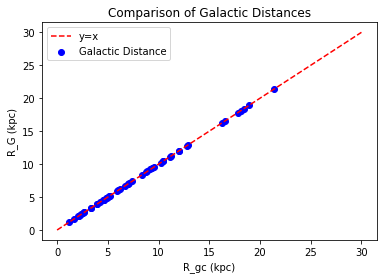

In [11]:
valid_R_G_data = harris_vdb_k21_merged[~harris_vdb_k21_merged['R_G'].isna()]
display(valid_R_G_data)
display(valid_R_G_data.shape)
display(valid_R_G_data[['ID', 'R_G']])
plt.scatter(valid_R_G_data['R_gc'], valid_R_G_data['R_G'], label='Galactic Distance', color='blue')
plt.plot([0, 30], [0, 30], color='red', linestyle='--', label='y=x')
plt.xlabel('R_gc (kpc)')
plt.ylabel('R_G (kpc)')
plt.title('Comparison of Galactic Distances')
plt.legend()
plt.show()

In [12]:
display((valid_R_G_data['R_gc'] - valid_R_G_data['R_G']).abs().max())

0.0

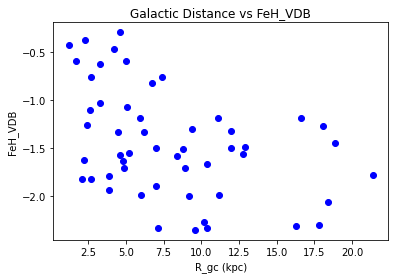

In [13]:
plt.scatter(harris_vdb_k21_merged['R_gc'], harris_vdb_k21_merged['FeH_VDB'], color='blue')
plt.xlabel('R_gc (kpc)')
plt.ylabel('FeH_VDB')
plt.title('Galactic Distance vs FeH_VDB')
plt.show()

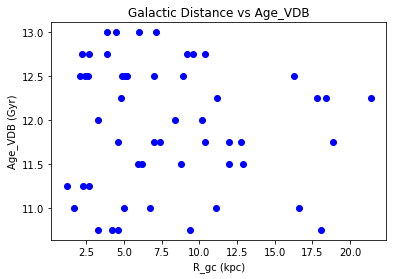

In [14]:
plt.scatter(harris_vdb_k21_merged['R_gc'], harris_vdb_k21_merged['Age_VDB'], color='blue')
plt.xlabel('R_gc (kpc)')
plt.ylabel('Age_VDB (Gyr)')
plt.title('Galactic Distance vs Age_VDB')
plt.show()

In [20]:
summary = pd.DataFrame({
    'Table': ['harris_merged', 'VandenBerg Table 2', 'Krause21'],
    'Rows': [harris_merged.shape[0], VDB.shape[0], Krause21.shape[0]],
    'Unique IDs': [harris_merged['NGC_number'].nunique(), VDB['NGC_number'].nunique(), Krause21['NGC_number'].nunique()],
    'Unmatched IDs': [harris_merged['NGC_number'].isna().sum(), VDB['NGC_number'].isna().sum(), Krause21['NGC_number'].isna().sum()],
    'Duplicates': [harris_merged['NGC_number'].dropna().duplicated().sum(), VDB['NGC_number'].dropna().duplicated().sum(), Krause21['NGC_number'].dropna().duplicated().sum()]
})
display(summary)


,Table,Rows,Unique IDs,Unmatched IDs,Duplicates
0,harris_merged,157,104,53,0
1,VandenBerg Table 2,55,52,3,0
2,Krause21,61,58,3,0


In [ ]:
lookup = {'Arp21': 'Arp 2', 'Ter8': 'Terzan 8', 'Pal12': 'Pal 12', 'Palomar12' : 'Pal 12', 'Ruprecht106' : 'Rup 106', 'Terzan7' : 'Terzan 7'}